# m08 - Two Suitability Products: Cross-Source Transfer and Downscaling Validation

The warehouse holds two independent suitability products for six crops (rice, maize, cassava, soybean, oil palm, sugarcane):

* **GAEZ v5** index at 30 arc-seconds (~1 km; the first round of experiments used its ~9 km version).
* **Global Crop Suitability 2024** (GCS), ~1 km native resolution, a different model and different inputs.

Questions:

1. **A. Agreement.** How well do the two products agree at the 1 km cell level and averaged over the ~9 km GAEZ pixels?
2. **B. Learnability.** Is GCS easier or harder to learn from the 14 physical drivers than GAEZ, and does it leak as much under random K-fold?
3. **C. Transfer.** A surrogate trained on one product, scored against the other (rank correlation, pixel-grouped CV).
4. **D. Local detail.** Inside each ~9 km pixel, do GAEZ, its surrogates and GCS (an independent 1 km product) agree on
   which cells are better? Each map's pixel mean is removed first, so only the local pattern is compared.
5. **E. Where do the products disagree?**

GCS values are multiplied by 10,000 so both products live on the same 0-10,000 scale. Cells without a GCS value are dropped.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df_all = E.load_table()
GC = E.GCS_CROPS
ok = df_all[E.gcs_cols()].notna().all(axis=1)
df = df_all[ok].reset_index(drop=True)
print(f"{len(df)} of {len(df_all)} cells have all six GCS values; {df['pix'].nunique()} ~9 km GAEZ pixels")
gaez = {c: df[E.target_col(c)].to_numpy() for c in GC}
gcs = {c: df[f"gcs2024_{c}"].to_numpy() * 10_000 for c in GC}

9043 of 9129 cells have all six GCS values; 162 ~9 km GAEZ pixels


## A. Agreement between the products

In [3]:
rows = []
for c in GC:
    cell_rho = E.spearman(gaez[c], gcs[c])
    pm_g = pd.Series(gaez[c]).groupby(df["pix"]).mean(); pm_c = pd.Series(gcs[c]).groupby(df["pix"]).mean()
    rows.append({"crop": c, "spearman_cell": cell_rho, "pearson_cell": np.corrcoef(gaez[c], gcs[c])[0, 1],
                 "spearman_pixel_mean": E.spearman(pm_g.to_numpy(), pm_c.to_numpy()),
                 "gaez_mean": gaez[c].mean(), "gcs_mean": gcs[c].mean(),
                 "gcs_within_pixel_share_of_variance": (gcs[c] - pd.Series(gcs[c]).groupby(df["pix"]).transform("mean")).var() / gcs[c].var()})
agree = pd.DataFrame(rows).set_index("crop")
E.save_table(agree.round(4), "m08_agreement", index=True)
agree.round(3)

,spearman_cell,pearson_cell,spearman_pixel_mean,gaez_mean,gcs_mean,gcs_within_pixel_share_of_variance
crop,,,,,,
rice,0.742,0.752,0.693,3010.392,6351.443,0.136
maize,0.357,0.370,0.363,1319.892,3014.363,0.251
cassava,0.357,0.474,0.334,3888.811,8443.415,0.188
soybean,-0.206,-0.096,-0.214,1750.298,1478.119,0.370
oilpalm,0.534,0.561,0.545,4378.299,6688.894,0.169
sugarcane,0.766,0.676,0.603,2318.578,7341.895,0.092


## B. Learnability of each product (5 models, random vs spatial CV)

In [4]:
targets = {**{f"gaez:{c}": gaez[c] for c in GC}, **{f"gcs:{c}": gcs[c] for c in GC}}
MODELS = ["ridge", "knn", "et", "hgb", "xgb"]
SCHEMES = ["random", "block10", "pixel"]
res, oof = E.run_grid(df, targets, MODELS, SCHEMES, n_repeats=2, keep_oof=True)
res[["source", "crop"]] = res["target"].str.split(":", expand=True)
E.save_table(res.drop(columns="target"), "m08_learnability_raw")
tab = res.groupby(["source", "model", "scheme"])["r2"].mean().unstack("scheme")[SCHEMES]
tab["leakage_gap"] = tab["random"] - tab["pixel"]
E.save_table(tab.round(4), "m08_learnability", index=True)
tab.round(3)

360 tasks (5 models x 12 targets x 3 schemes x 2 repeats), 14 features


done in 100 s


scheme        random  block10  pixel  leakage_gap
source model                                     
gaez   et      0.915    0.821  0.823        0.092
       hgb     0.896    0.811  0.804        0.092
       knn     0.869    0.731  0.745        0.125
       ridge   0.638    0.599  0.602        0.035
       xgb     0.888    0.808  0.808        0.081
gcs    et      0.917    0.772  0.783        0.134
       hgb     0.893    0.749  0.760        0.133
       knn     0.853    0.687  0.711        0.142
       ridge   0.557    0.500  0.517        0.040
       xgb     0.878    0.746  0.754        0.123

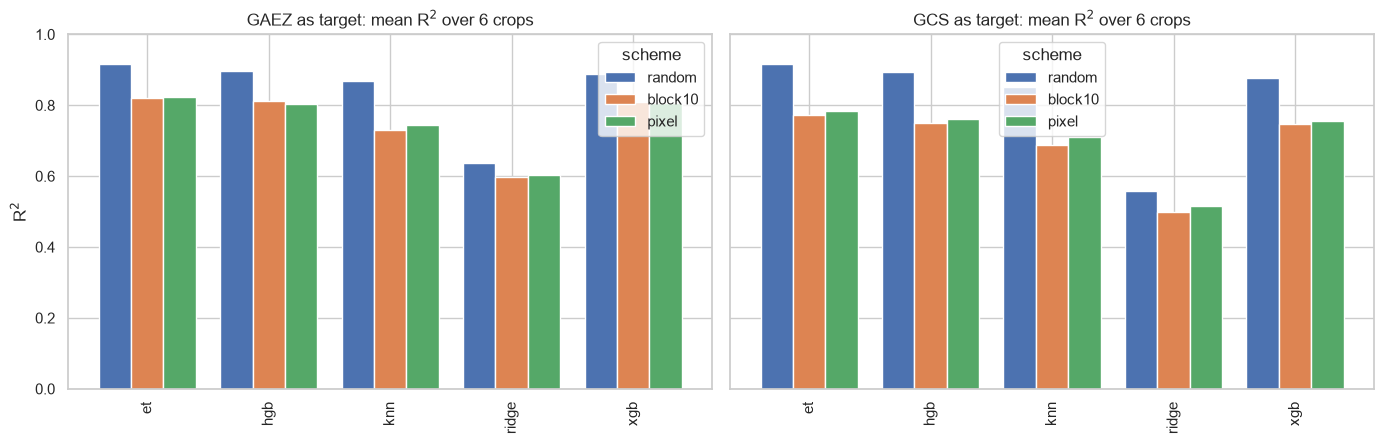

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, src in zip(axes, ["gaez", "gcs"]):
    tab.loc[src][SCHEMES].plot.bar(ax=ax, width=0.8)
    ax.set(title=f"{src.upper()} as target: mean R$^2$ over 6 crops", xlabel="", ylabel="R$^2$", ylim=(0, 1))
plt.tight_layout()
E.save_fig(fig, "m08_learnability")
plt.show()

## C. Cross-source transfer (pixel CV, hist-boosting and extra-trees surrogates)
Spearman rho between each surrogate's out-of-fold predictions and each product.

In [6]:
rows = []
for m in ["hgb", "et"]:
    for c in GC:
        pg = np.mean([oof[(m, f"gaez:{c}", "pixel", r)] for r in range(2)], axis=0)
        pc = np.mean([oof[(m, f"gcs:{c}", "pixel", r)] for r in range(2)], axis=0)
        rows.append({"model": m, "crop": c,
                     "raw GAEZ vs GCS": E.spearman(gaez[c], gcs[c]),
                     "GAEZ-surrogate vs GAEZ": E.spearman(pg, gaez[c]),
                     "GAEZ-surrogate vs GCS": E.spearman(pg, gcs[c]),
                     "GCS-surrogate vs GCS": E.spearman(pc, gcs[c]),
                     "GCS-surrogate vs GAEZ": E.spearman(pc, gaez[c])})
tr = pd.DataFrame(rows)
E.save_table(tr.round(4), "m08_transfer", index=False)
tr[tr.model == "hgb"].set_index("crop").drop(columns="model").round(3)

,raw GAEZ vs GCS,GAEZ-surrogate vs GAEZ,GAEZ-surrogate vs GCS,GCS-surrogate vs GCS,GCS-surrogate vs GAEZ
crop,,,,,
rice,0.742,0.908,0.811,0.951,0.760
maize,0.357,0.894,0.427,0.837,0.451
cassava,0.357,0.910,0.326,0.769,0.402
soybean,-0.206,0.891,-0.195,0.802,-0.239
oilpalm,0.534,0.906,0.564,0.893,0.559
sugarcane,0.766,0.905,0.775,0.893,0.786


In [7]:
mean_tr = tr.groupby("model").mean(numeric_only=True).round(3)
mean_tr

,raw GAEZ vs GCS,GAEZ-surrogate vs GAEZ,GAEZ-surrogate vs GCS,GCS-surrogate vs GCS,GCS-surrogate vs GAEZ
model,,,,,
et,0.425,0.908,0.464,0.876,0.463
hgb,0.425,0.902,0.451,0.858,0.453


## D. Local detail: within-pixel agreement

For every cell take its departure from the mean of its ~9 km GAEZ pixel, in every map. At 1 km GAEZ has its own
within-pixel pattern, so this compares the local detail of GAEZ, of its surrogates and of GCS (an independent 1 km
product) directly.

Baselines: the best *single raw feature*'s within-pixel departure (sign-agnostic, so the strongest of 14 trivial predictors).

In [8]:
def demean(v):
    return v - pd.Series(v).groupby(df["pix"]).transform("mean").to_numpy()

feat_anom = {f: demean(df[f].fillna(df[f].median()).to_numpy()) for f in E.feature_columns()}
rows = []
for c in GC:
    ref = demean(gcs[c])
    best_feat, best_rho = max(((f, abs(E.spearman(a, ref))) for f, a in feat_anom.items()), key=lambda t: t[1])
    row = {"crop": c, "best single feature": best_feat, "|rho| best single feature": best_rho,
           "within-pixel rho(raw GAEZ, GCS)": E.spearman(demean(gaez[c]), ref)}
    for m in ["hgb", "et", "xgb"]:
        pg = np.mean([oof[(m, f"gaez:{c}", "pixel", r)] for r in range(2)], axis=0)
        pc = np.mean([oof[(m, f"gcs:{c}", "pixel", r)] for r in range(2)], axis=0)
        row[f"{m}: GAEZ-surrogate"] = E.spearman(demean(pg), ref)
        row[f"{m}: GCS-surrogate"] = E.spearman(demean(pc), ref)
    rows.append(row)
within = pd.DataFrame(rows).set_index("crop")
E.save_table(within.round(4), "m08_within_pixel", index=True)
within.round(3)

,best single feature,|rho| best single feature,"within-pixel rho(raw GAEZ, GCS)",hgb: GAEZ-surrogate,hgb: GCS-surrogate,et: GAEZ-surrogate,et: GCS-surrogate,xgb: GAEZ-surrogate,xgb: GCS-surrogate
crop,,,,,,,,,
rice,elevation_mean_m,0.547,0.432,0.451,0.655,0.461,0.687,0.452,0.660
maize,bio1_temp_mean_c,0.163,-0.036,0.031,0.477,0.041,0.561,0.042,0.464
cassava,bio12_precip_annual_mm,0.160,0.245,0.123,0.362,0.122,0.445,0.111,0.355
soybean,bio12_precip_annual_mm,0.203,-0.079,-0.042,0.414,-0.035,0.481,-0.039,0.412
oilpalm,elevation_mean_m,0.301,0.157,0.198,0.643,0.200,0.691,0.191,0.622
sugarcane,bio12_precip_annual_mm,0.263,0.320,0.231,0.408,0.258,0.511,0.225,0.396


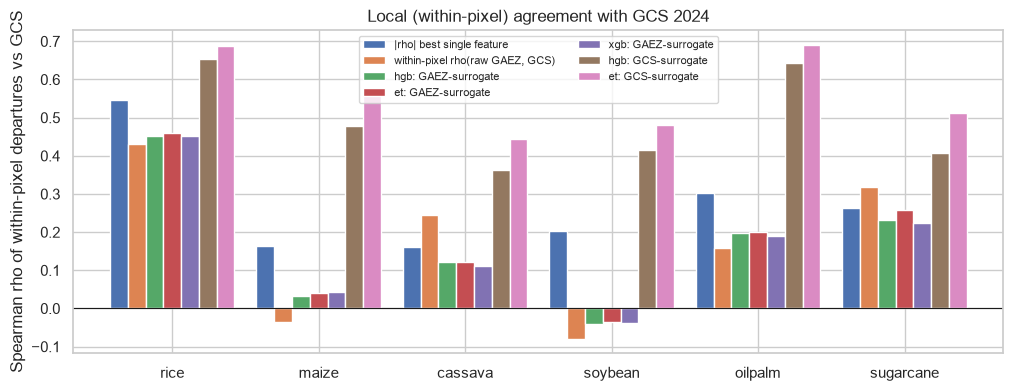

In [9]:
cols = ["|rho| best single feature", "within-pixel rho(raw GAEZ, GCS)", "hgb: GAEZ-surrogate", "et: GAEZ-surrogate", "xgb: GAEZ-surrogate",
        "hgb: GCS-surrogate", "et: GCS-surrogate"]
fig, ax = plt.subplots(figsize=(12, 4.2))
within[cols].plot.bar(ax=ax, width=0.85)
ax.axhline(0, color="k", lw=0.8)
ax.set(ylabel="Spearman rho of within-pixel departures vs GCS", xlabel="", title="Local (within-pixel) agreement with GCS 2024")
ax.legend(fontsize=8, ncol=2)
plt.xticks(rotation=0)
E.save_fig(fig, "m08_within_pixel")
plt.show()

## E. Where do the two products disagree?
Percentile rank of the GAEZ surrogate minus percentile rank of GCS (positive = GAEZ rates the cell higher than GCS does).

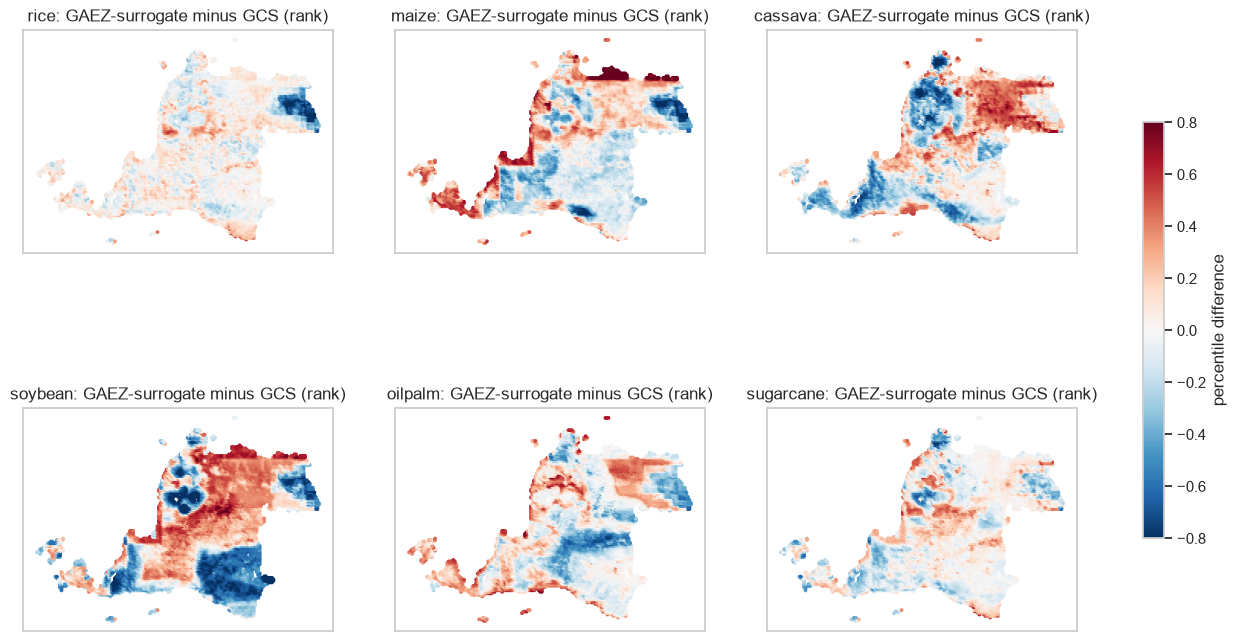

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), GC):
    pg = np.mean([oof[("hgb", f"gaez:{c}", "pixel", r)] for r in range(2)], axis=0)
    d = pd.Series(pg).rank(pct=True).to_numpy() - pd.Series(gcs[c]).rank(pct=True).to_numpy()
    sc = ax.scatter(df["lon"], df["lat"], c=d, s=3, cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    ax.set(title=f"{c}: GAEZ-surrogate minus GCS (rank)", aspect="equal"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axes, shrink=0.6, label="percentile difference")
E.save_fig(fig, "m08_disagreement_maps")
plt.show()